In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Linear Regression Model
from sklearn.linear_model import LinearRegression
# Train Test Package
from sklearn.model_selection import train_test_split
# Feature Scaling
from sklearn.preprocessing import StandardScaler
# Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [13]:
df = pd.read_csv('Dataset/Real estate.csv')
df.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [14]:
df.isnull().sum()

No                                        0
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64

In [15]:
df.columns

Index(['No', 'X1 transaction date', 'X2 house age',
       'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude',
       'Y house price of unit area'],
      dtype='object')

<Axes: ylabel='X6 longitude'>

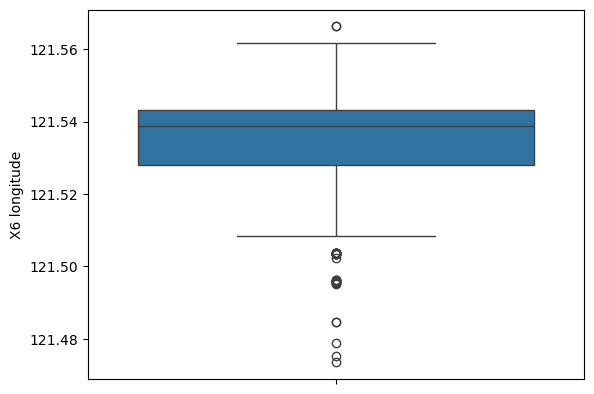

In [16]:
sns.boxplot(df['X6 longitude'])

In [17]:
df = df.drop(columns=['No', 'X1 transaction date'])

In [19]:
# df_corr = df.corr(method='spearman')
df_corr = df.corr(method='pearson')

In [24]:
plt.figure(figsize=(10, 4))
sns.heatmap(df_corr, annot=True)
plt.close()

## Feature and Target

In [26]:
features = ['X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores', 
            'X5 latitude', 'X6 longitude']
target = 'Y house price of unit area'

In [28]:
X = df[features]
Y = df[target]

## Train Test Split

In [31]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

## Feature Scaling

In [ ]:
'''
scaler.fit_transform(X_train)
    -> fit_transform(training data)
        -> fit -> Learning -> Calculates mean and sd
        -> transform -> Implement -> Implements mean and sd into formula ((Xi - mean)/sd)

scaler.transform(X_test)
    -> transform(testing data)
        -> transform -> implement -> ((Xi - mean)/sd)
'''

In [32]:
scaler = StandardScaler()
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)

## Model Implementation

In [35]:
model = LinearRegression()

In [ ]:
'''
- X_train -> Question
- Y_train -> Answer

- X_test -> Exam Question

- fit(training data) -> X_train, Y_Train -> Model Learning Phase
- predict(testing data) -> X_test
'''

In [37]:
model.fit(X_train_scale, Y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [38]:
Y_pred = model.predict(X_test_scale)

In [51]:
beta_0 = model.intercept_
beta_1 = model.coef_

print(f'Intercept: {beta_0}')
print(f'Slope / Coefficient: {beta_1}')

Intercept: 38.39154078549814
Slope / Coefficient: [-3.06045213 -5.53623761  3.25926406  2.94298597 -0.35743672]


## Metrics

In [41]:
mae = mean_absolute_error(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, Y_pred)

In [42]:
print(f'Mean Absolute Error: {mae}')
print(f'Mean Squared Error: {mse}')
print(f'Root Mean Squared Error: {rmse}')
print(f'R2 Score: {r2}')

Mean Absolute Error: 5.350138374356212
Mean Squared Error: 54.580945200862146
Root Mean Squared Error: 7.3878917967754605
R2 Score: 0.6746481382828176


## Visualization

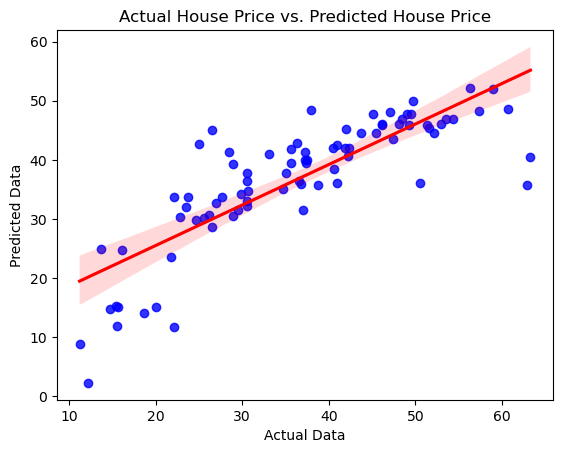

In [48]:
sns.regplot(x=Y_test, y=Y_pred, color='blue', line_kws={'color': 'red'})
plt.xlabel('Actual Data')
plt.ylabel('Predicted Data')
plt.title('Actual House Price vs. Predicted House Price')
plt.show()